# ECG Classification — PTB-XL (100 Hz)

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ast
import json
import wfdb
import time

from pathlib import Path
from tqdm.auto import tqdm


/usr/lib/python3/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
DATA_DIR = Path("data/")

MODEL_DIR = Path("data/processed/ptbxl_100hz_5class")
MODEL_DIR.mkdir(parents=True, exist_ok=True)


In [6]:
df = pd.read_csv(DATA_DIR / "ptbxl_database.csv")

scp = pd.read_csv(
    DATA_DIR / "scp_statements.csv",
    index_col=0
)

print("Dataset shape:", df.shape)
print("SCP statements shape:", scp.shape)


Dataset shape: (21837, 28)
SCP statements shape: (71, 12)


In [7]:
df.head()


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [8]:
scp.head()


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


In [9]:
scp

,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7
...,...,...,...,...,...,...,...,...,...,...,...,...
BIGU,"bigeminal pattern (unknown origin, SV or Ventr...",NaN,NaN,1.0,NaN,NaN,Statements related to ectopic rhythm abnormali...,"bigeminal pattern (unknown origin, SV or Ventr...",NaN,NaN,NaN,NaN
AFLT,atrial flutter,NaN,NaN,1.0,NaN,NaN,Statements related to impulse formation (abnor...,atrial flutter,51.0,MDC_ECG_RHY_ATR_FLUT,NaN,NaN
SVTAC,supraventricular tachycardia,NaN,NaN,1.0,NaN,NaN,Statements related to impulse formation (abnor...,supraventricular tachycardia,55.0,MDC_ECG_RHY_SV_TACHY,NaN,D3-31290
PSVT,paroxysmal supraventricular tachycardia,NaN,NaN,1.0,NaN,NaN,Statements related to impulse formation (abnor...,paroxysmal supraventricular tachycardia,NaN,MDC_ECG_RHY_SV_TACHY_PAROX,NaN,NaN


In [10]:
assert df["ecg_id"].is_unique
assert df["patient_id"].notna().all()
assert df["strat_fold"].isin(range(1, 11)).all()
assert df["filename_lr"].notna().all()

print("Total ECGs:", len(df))
print("Unique patients:", df["patient_id"].nunique())

print("\nFold distribution:")
print(df["strat_fold"].value_counts().sort_index())


Total ECGs: 21837
Unique patients: 18885

Fold distribution:
strat_fold
1     2177
2     2184
3     2194
4     2175
5     2176
6     2178
7     2178
8     2179
9     2193
10    2203
Name: count, dtype: int64


## Diagnostic Labels

In [11]:
scp = scp[scp["diagnostic"] == 1]

selected_labels = [
    "NORM", "MI", "STTC", "CD", "HYP"
]

df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)


In [12]:
def get_diagnostic_classes(codes):

    classes = set()

    for code in codes:

        if code in scp.index:

            group = scp.loc[code, "diagnostic_class"]

            if group in selected_labels:

                classes.add(group)

    return list(classes)


In [13]:
df["diagnostic_classes"] = df["scp_codes"].apply(
    get_diagnostic_classes
)

for label in selected_labels:

    df[label] = df["diagnostic_classes"].apply(
        lambda classes: int(label in classes)
    )

df[["ecg_id"] + selected_labels].head()


,ecg_id,NORM,MI,STTC,CD,HYP
0,1,1,0,0,0,0
1,2,1,0,0,0,0
2,3,1,0,0,0,0
3,4,1,0,0,0,0
4,5,1,0,0,0,0


In [14]:
# Exclude ECGs without any diagnostic superclass.

original_count = len(df)

df = df[df[selected_labels].sum(axis=1) > 0].copy()

print("Excluded ECGs:", original_count - len(df))
print("Selected ECGs:", len(df))

print("NORM with another label:",
      ((df["NORM"] == 1) &
       (df[selected_labels].sum(axis=1) > 1)).sum())


Excluded ECGs: 407
Selected ECGs: 21430
NORM with another label: 445


## Dataset Splitting

In [15]:
train_df = df[df["strat_fold"].between(1, 8)].copy()
val_df = df[df["strat_fold"] == 9].copy()
test_df = df[df["strat_fold"] == 10].copy()


In [16]:
assert set(train_df.patient_id).isdisjoint(val_df.patient_id)
assert set(train_df.patient_id).isdisjoint(test_df.patient_id)
assert set(val_df.patient_id).isdisjoint(test_df.patient_id)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nNo patient leakage detected.")


Training records: 17111
Validation records: 2156
Testing records: 2163

No patient leakage detected.


In [17]:
distribution = pd.DataFrame({
    "Train": train_df[selected_labels].sum(),
    "Validation": val_df[selected_labels].sum(),
    "Test": test_df[selected_labels].sum()
})

print(distribution)

assert (distribution > 0).all().all()

for split, dataframe in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    assert (distribution[split] < len(dataframe)).all()


      Train  Validation  Test
NORM   7607         957   964
MI     4389         544   553
STTC   4193         534   523
CD     3912         497   498
HYP    2121         271   263


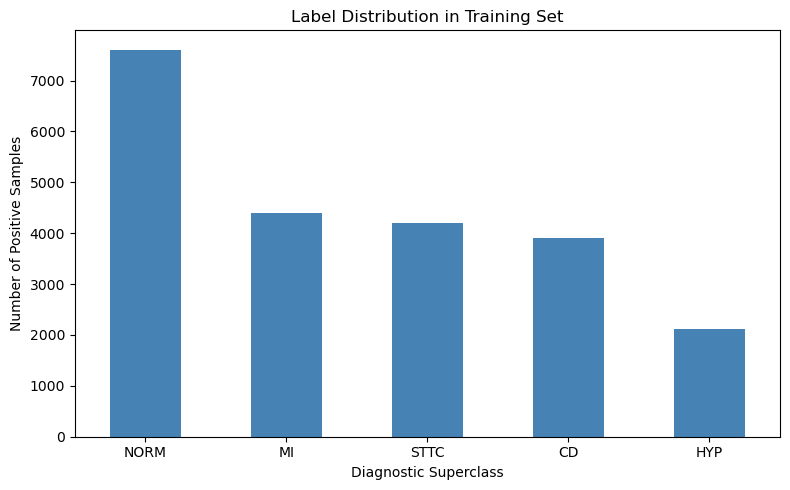

In [18]:
distribution["Train"].plot(
    kind="bar",
    color="steelblue",
    figsize=(8, 5)
)

plt.title("Label Distribution in Training Set")
plt.xlabel("Diagnostic Superclass")
plt.ylabel("Number of Positive Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [19]:
df.to_csv(
    MODEL_DIR / "training_index_with_folds.csv",
    index=False
)

with open(MODEL_DIR / "selected_labels.json", "w") as f:

    json.dump(selected_labels, f, indent=4)

distribution.to_csv(
    MODEL_DIR / "label_distribution.csv"
)


## Numerical ECG Signals

In [20]:
SAMPLING_RATE = 100
N_SAMPLES = 1000

LEAD_ORDER = [
    "I", "II", "III",
    "aVR", "aVL", "aVF",
    "V1", "V2", "V3",
    "V4", "V5", "V6"
]


In [21]:
def load_signal(filename):

    signal, metadata = wfdb.rdsamp(
        str(DATA_DIR / filename)
    )

    assert metadata["fs"] == SAMPLING_RATE
    assert signal.shape == (N_SAMPLES, 12)

    lead_names = [
        lead.lower()
        for lead in metadata["sig_name"]
    ]

    order = [
        lead_names.index(lead.lower())
        for lead in LEAD_ORDER
    ]

    # WFDB returns physical amplitudes in mV.
    assert all(
        unit.lower() == "mv"
        for unit in metadata["units"]
    )

    signal = signal[:, order].T.astype(np.float32)

    assert signal.shape == (12, N_SAMPLES)
    assert np.isfinite(signal).all()

    return signal


In [22]:
sample = train_df.iloc[0]

sample_signal = load_signal(sample["filename_lr"])

print("Signal shape:", sample_signal.shape)
print("Number of leads:", sample_signal.shape[0])
print("Samples per lead:", sample_signal.shape[1])
print("Minimum amplitude:", sample_signal.min())
print("Maximum amplitude:", sample_signal.max())

print("\nLabels:")
print(sample[selected_labels])


Signal shape: (12, 1000)
Number of leads: 12
Samples per lead: 1000
Minimum amplitude: -1.377
Maximum amplitude: 0.706

Labels:
NORM    1
MI      0
STTC    0
CD      0
HYP     0
Name: 0, dtype: object


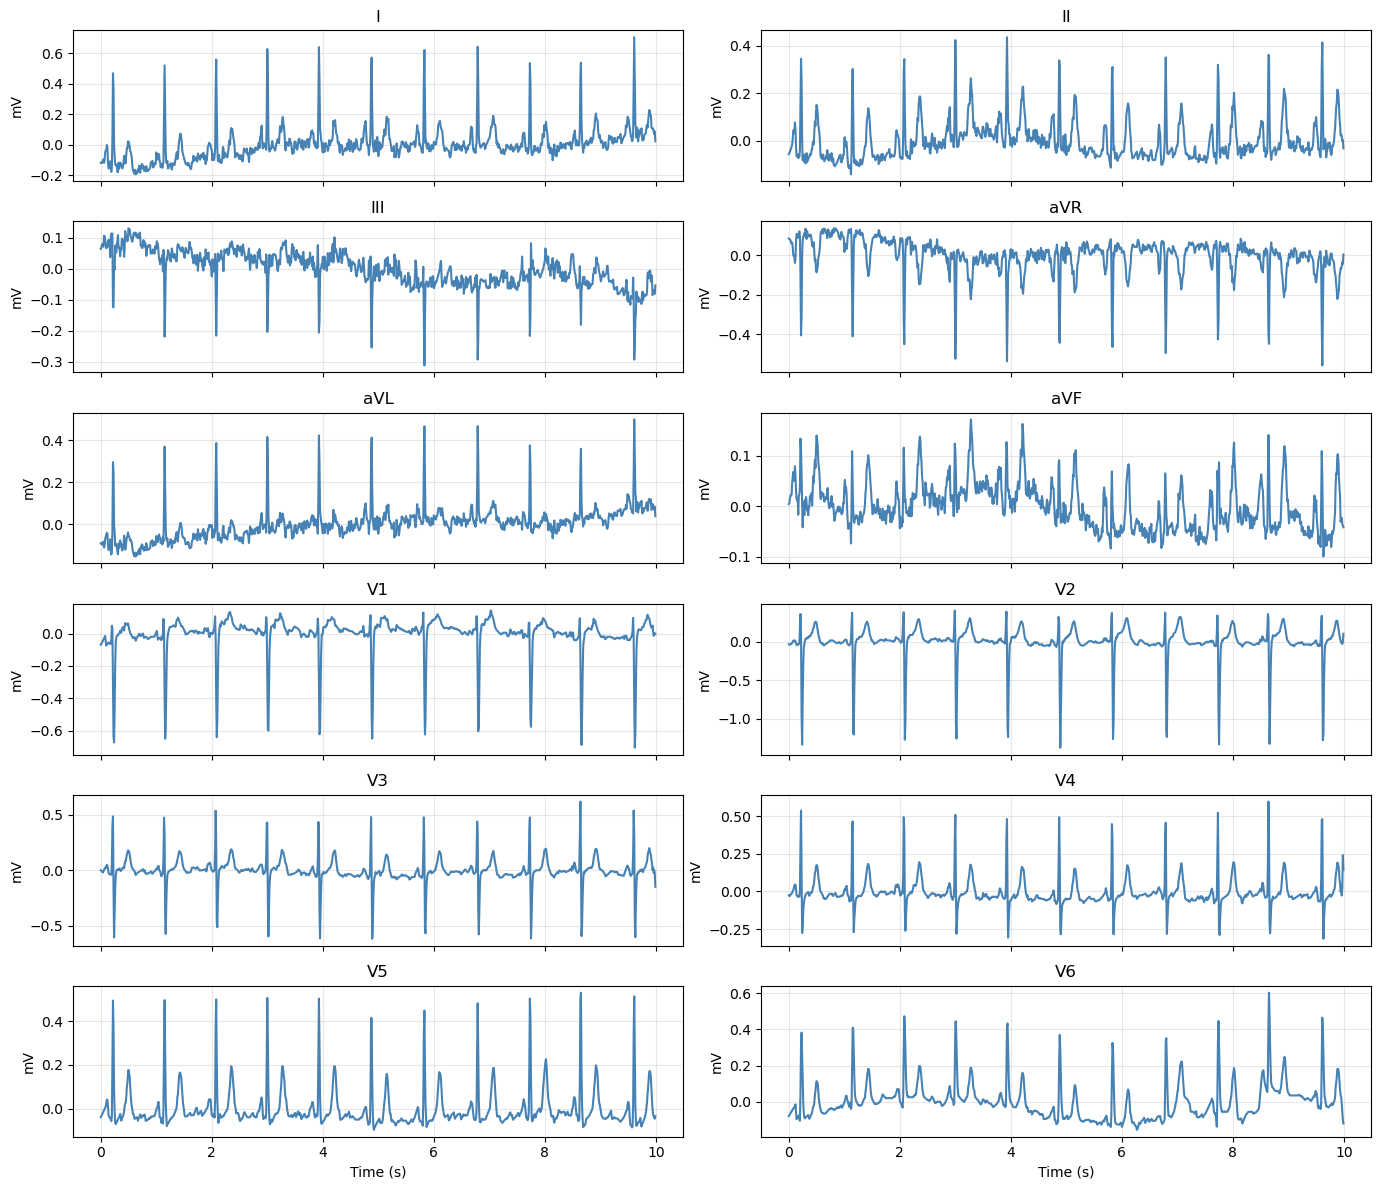

In [23]:
t = np.arange(N_SAMPLES) / SAMPLING_RATE

fig, axes = plt.subplots(
    6, 2, figsize=(14, 12), sharex=True
)

for i, ax in enumerate(axes.flat):

    ax.plot(t, sample_signal[i], color="steelblue")
    ax.set_title(LEAD_ORDER[i])
    ax.set_ylabel("mV")
    ax.grid(alpha=0.3)

for ax in axes[-1]:

    ax.set_xlabel("Time (s)")

plt.tight_layout()
plt.show()


In [24]:
def prepare_signals(dataframe, split_name):

    X = np.empty(
        (len(dataframe), 12, N_SAMPLES),
        dtype=np.float32
    )

    for i, filename in enumerate(
        tqdm(dataframe["filename_lr"],
             desc=f"Loading {split_name} signals")
    ):

        X[i] = load_signal(filename)

    return X


In [25]:
SIGNAL_DIR = MODEL_DIR / "signals"
SIGNAL_DIR.mkdir(exist_ok=True)

REBUILD_CACHE = False


In [26]:
def get_signals(dataframe, split_name):

    data_path = SIGNAL_DIR / f"X_{split_name}.npy"
    ids_path = SIGNAL_DIR / f"{split_name}_ids.npy"
    root_path = SIGNAL_DIR / f"{split_name}_root.txt"

    ids = dataframe["ecg_id"].to_numpy(dtype=np.int64)

    if not REBUILD_CACHE:

        if (data_path.exists() and ids_path.exists()
                and root_path.exists()
                and root_path.read_text() == str(DATA_DIR.resolve())):

            saved_ids = np.load(ids_path)

            if np.array_equal(saved_ids, ids):

                X = np.load(data_path, mmap_mode="r")

                if X.shape == (len(dataframe), 12, N_SAMPLES):

                    return X

    X = prepare_signals(dataframe, split_name)

    np.save(data_path, X)
    np.save(ids_path, ids)
    root_path.write_text(str(DATA_DIR.resolve()))

    return np.load(data_path, mmap_mode="r")


In [27]:
start = time.perf_counter()

X_train_signal = get_signals(train_df, "train")
X_val_signal = get_signals(val_df, "val")

load_time = time.perf_counter() - start

y_train = train_df[selected_labels].to_numpy(
    dtype=np.uint8
)

y_val = val_df[selected_labels].to_numpy(
    dtype=np.uint8
)

print("Training:", X_train_signal.shape, y_train.shape)
print("Validation:", X_val_signal.shape, y_val.shape)

print("Loading time:", round(load_time, 2), "seconds")


Loading val signals: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2156/2156 [00:10<00:00, 203.48it/s]

Training: (17111, 12, 1000) (17111, 5)
Validation: (2156, 12, 1000) (2156, 5)
Loading time: 96.53 seconds


## Normalization

In [28]:
# Calculate mean and standard deviation using training ECGs.

signal_mean = np.array([
    X_train_signal[:, i, :].mean(dtype=np.float64)
    for i in range(12)
], dtype=np.float32).reshape(12, 1)

signal_std = np.array([
    X_train_signal[:, i, :].std(dtype=np.float64)
    for i in range(12)
], dtype=np.float32).reshape(12, 1)

assert np.isfinite(signal_mean).all()
assert np.isfinite(signal_std).all()
assert (signal_std > 0).all()

print("Mean:", signal_mean.ravel())
print("Standard deviation:", signal_std.ravel())

np.savez(
    MODEL_DIR / "normalization.npz",
    mean=signal_mean,
    std=signal_std,
    leads=LEAD_ORDER
)


Mean: [-0.0020683  -0.00152101  0.00054731  0.00177711 -0.00125359 -0.00046438
  0.00017504 -0.00095182 -0.001564   -0.00135743 -0.0008031  -0.0024237 ]
Standard deviation: [0.1655449  0.15922    0.16553845 0.13975386 0.14513437 0.13961244
 0.23441413 0.3342103  0.32844296 0.29273918 0.2720324  0.28088325]


## PCA Features

In [29]:
import joblib

from sklearn.decomposition import PCA


In [30]:
X_train = (
    (X_train_signal - signal_mean) / signal_std
).reshape(len(train_df), -1)

X_val = (
    (X_val_signal - signal_mean) / signal_std
).reshape(len(val_df), -1)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

assert X_train.shape[1] == 12000
assert X_val.shape[1] == 12000


Training features: (17111, 12000)
Validation features: (2156, 12000)


In [31]:
pca = PCA(
    n_components=256,
    svd_solver="randomized",
    random_state=42
)

start = time.perf_counter()

X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)

pca_time = time.perf_counter() - start

print("Training PCA features:", X_train_pca.shape)
print("Validation PCA features:", X_val_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())
print("PCA time:", round(pca_time, 2), "seconds")

joblib.dump(pca, MODEL_DIR / "pca.pkl")

del X_train, X_val

preprocessing_times = pd.DataFrame({
    "Step": ["Signal loading", "PCA"],
    "Time (s)": [load_time, pca_time]
})

preprocessing_times.to_csv(
    MODEL_DIR / "preprocessing_times.csv",
    index=False
)


Training PCA features: (17111, 256)
Validation PCA features: (2156, 256)
Explained variance: 0.5618937
PCA time: 227.21 seconds


## Logistic Regression

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    hamming_loss,
    precision_recall_curve,
    multilabel_confusion_matrix,
    ConfusionMatrixDisplay
)


In [33]:
lr_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ),
    n_jobs=2,
    verbose=10
)


In [34]:
start = time.perf_counter()

lr_model.fit(X_train_pca, y_train)

lr_time = time.perf_counter() - start

print("Training time:", round(lr_time, 2), "seconds")


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    1.6s
[Parallel(n_jobs=2)]: Done   3 out of   5 | elapsed:    2.6s remaining:    1.7s


Training time: 4.23 seconds


[Parallel(n_jobs=2)]: Done   5 out of   5 | elapsed:    4.1s finished


In [35]:
print("Logistic Regression training completed.")

joblib.dump(
    lr_model,
    MODEL_DIR / "logistic_regression_pca.pkl"
)


Logistic Regression training completed.


['data/processed/ptbxl_100hz_5class/logistic_regression_pca.pkl']

In [36]:
lr_val_probs = lr_model.predict_proba(X_val_pca)

lr_val_preds = (lr_val_probs >= 0.5).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, lr_val_probs, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, lr_val_probs,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, lr_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, lr_val_preds,
               average="micro", zero_division=0))


Macro AUROC: 0.5086495278838046
Macro AUPRC: 0.27974873307250425
Macro F1: 0.05377041329474712
Micro F1: 0.09895997478726758


## SVM

In [37]:
from sklearn.svm import LinearSVC


In [38]:
svm_model = OneVsRestClassifier(
    LinearSVC(
        C=1.0,
        dual=False,
        max_iter=5000,
        random_state=42
    ),
    n_jobs=2,
    verbose=10
)


In [39]:
start = time.perf_counter()

svm_model.fit(X_train_pca, y_train)

svm_time = time.perf_counter() - start

print("Training time:", round(svm_time, 2), "seconds")


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.7s
[Parallel(n_jobs=2)]: Done   3 out of   5 | elapsed:    1.7s remaining:    1.2s


Training time: 3.22 seconds


[Parallel(n_jobs=2)]: Done   5 out of   5 | elapsed:    3.1s finished


In [40]:
print("SVM training completed.")

joblib.dump(svm_model, MODEL_DIR / "linear_svm_pca.pkl")


SVM training completed.


['data/processed/ptbxl_100hz_5class/linear_svm_pca.pkl']

In [41]:
svm_val_scores = svm_model.decision_function(X_val_pca)

svm_val_preds = (svm_val_scores >= 0).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, svm_val_scores, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, svm_val_scores,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, svm_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, svm_val_preds,
               average="micro", zero_division=0))


Macro AUROC: 0.5086029013902553
Macro AUPRC: 0.2803207803280526
Macro F1: 0.04625692068429238
Micro F1: 0.09177820267686425


## Random Forest

In [42]:
from sklearn.ensemble import RandomForestClassifier


In [43]:
rf_model = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),
    n_jobs=1,
    verbose=10
)


In [44]:
start = time.perf_counter()

rf_model.fit(X_train_pca, y_train)

rf_time = time.perf_counter() - start

print("Training time:", round(rf_time, 2), "seconds")


[Parallel(n_jobs=1)]: Done   1 tasks      | elapsed:    3.1s
[Parallel(n_jobs=1)]: Done   4 tasks      | elapsed:   13.0s


Training time: 16.66 seconds


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   16.7s finished


In [45]:
print("Random Forest training completed.")

joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest_pca.pkl"
)


Random Forest training completed.


['data/processed/ptbxl_100hz_5class/random_forest_pca.pkl']

In [46]:
rf_val_probs = rf_model.predict_proba(X_val_pca)

rf_val_preds = (rf_val_probs >= 0.5).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, rf_val_probs, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, rf_val_probs,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, rf_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, rf_val_preds,
               average="micro", zero_division=0))


Macro AUROC: 0.6711178576317757
Macro AUPRC: 0.4139695788926727
Macro F1: 0.1838473507172484
Micro F1: 0.35700197238658776


In [47]:
# Common metrics for model comparison.

def get_metrics(y_true, scores, threshold):

    y_preds = (scores >= threshold).astype(int)

    return {
        "Macro AUROC": roc_auc_score(
            y_true, scores, average="macro"
        ),

        "Macro AUPRC": average_precision_score(
            y_true, scores, average="macro"
        ),

        "Macro F1": f1_score(
            y_true, y_preds, average="macro", zero_division=0
        ),

        "Micro F1": f1_score(
            y_true, y_preds, average="micro", zero_division=0
        ),

        "Macro Precision": precision_score(
            y_true, y_preds, average="macro", zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true, y_preds, average="macro", zero_division=0
        ),

        "Binary Accuracy": 1 - hamming_loss(y_true, y_preds),

        "Exact Match Accuracy": accuracy_score(y_true, y_preds)
    }


In [48]:
baseline_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        **get_metrics(y_val, lr_val_probs, 0.5)
    },
    {
        "Model": "SVM",
        **get_metrics(y_val, svm_val_scores, 0.0)
    },
    {
        "Model": "Random Forest",
        **get_metrics(y_val, rf_val_probs, 0.5)
    }
])

display(baseline_results.round(4))

del X_train_pca, X_val_pca


,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1,Macro Precision,Macro Recall,Binary Accuracy,Exact Match Accuracy
0,Logistic Regression,0.5086,0.2797,0.0538,0.0990,0.4498,0.0352,0.7348,0.0659
1,SVM,0.5086,0.2803,0.0463,0.0918,0.2857,0.0307,0.7356,0.0626
2,Random Forest,0.6711,0.4140,0.1838,0.3570,0.5533,0.1693,0.7581,0.2982


## 1D CNN

In [49]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader


In [50]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [51]:
class ECGSignalDataset(Dataset):

    def __init__(self, signals, dataframe, labels):

        self.signals = signals

        self.targets = dataframe[labels].to_numpy(
            dtype=np.float32, copy=True
        )

    def __len__(self):

        return len(self.signals)

    def __getitem__(self, idx):

        signal = self.signals[idx]

        signal = (signal - signal_mean) / signal_std

        signal = torch.from_numpy(signal).float()

        target = torch.from_numpy(self.targets[idx])

        return signal, target


In [52]:
train_dataset = ECGSignalDataset(
    X_train_signal, train_df, selected_labels
)

val_dataset = ECGSignalDataset(
    X_val_signal, val_df, selected_labels
)


In [53]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


In [54]:
signals, labels = next(iter(train_loader))

print("Signal batch shape:", signals.shape)
print("Label batch shape:", labels.shape)


Signal batch shape: torch.Size([16, 12, 1000])
Label batch shape: torch.Size([16, 5])


In [55]:
class ECGCNN1D(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        def conv_block(in_channels, out_channels):

            return nn.Sequential(
                nn.Conv1d(
                    in_channels,
                    out_channels,
                    kernel_size=5,
                    padding=2,
                    bias=False
                ),
                nn.BatchNorm1d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool1d(2)
            )

        self.features = nn.Sequential(
            conv_block(12, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256)
        )

        self.pool = nn.AdaptiveAvgPool1d(8)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x


In [56]:
model = ECGCNN1D(
    num_classes=len(selected_labels)
).to(device)

print(model)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))


ECGCNN1D(
  (features): Sequential(
    (0): Sequential(
      (0): Conv1d(12, 32, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, c

In [57]:
EPOCHS = 30
LEARNING_RATE = 0.0003
PATIENCE = 5


In [58]:
criterion = nn.BCEWithLogitsLoss()


In [59]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)


In [60]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)


In [61]:
BEST_MODEL_PATH = MODEL_DIR / "cnn_1d_best.pt"


In [62]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0.0

    for signals, targets in tqdm(loader, desc="Training", leave=False):

        signals = signals.to(device)
        targets = targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Forward propagation
        logits = model(signals)

        # Calculate loss
        loss = criterion(logits, targets)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * signals.size(0)

    return running_loss / len(loader.dataset)


In [63]:
def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_targets = []
    all_probs = []

    with torch.no_grad():

        for signals, targets in tqdm(
            loader, desc="Evaluating", leave=False
        ):

            signals = signals.to(device)
            targets = targets.to(device)

            logits = model(signals)

            loss = criterion(logits, targets)

            probs = torch.sigmoid(logits)

            running_loss += loss.item() * signals.size(0)

            all_targets.append(targets.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    y_true = np.concatenate(all_targets, axis=0)
    y_probs = np.concatenate(all_probs, axis=0)

    y_preds = (y_probs >= 0.5).astype(int)

    metrics = {
        "loss": running_loss / len(loader.dataset),

        "macro_auroc": roc_auc_score(
            y_true, y_probs, average="macro"
        ),

        "macro_auprc": average_precision_score(
            y_true, y_probs, average="macro"
        ),

        "macro_f1": f1_score(
            y_true, y_preds,
            average="macro", zero_division=0
        ),

        "micro_f1": f1_score(
            y_true, y_preds,
            average="micro", zero_division=0
        )
    }

    return metrics, y_true, y_probs


In [64]:
history = {
    "train_loss": [],
    "val_loss": [],
    "macro_auroc": [],
    "macro_auprc": [],
    "macro_f1": [],
    "micro_f1": []
}

best_auprc = -np.inf
best_epoch = 0
epochs_without_improvement = 0


In [65]:
start = time.perf_counter()

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_metrics, _, _ = evaluate_model(
        model,
        val_loader,
        criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["macro_auroc"].append(val_metrics["macro_auroc"])
    history["macro_auprc"].append(val_metrics["macro_auprc"])
    history["macro_f1"].append(val_metrics["macro_f1"])
    history["micro_f1"].append(val_metrics["micro_f1"])

    scheduler.step(val_metrics["macro_auprc"])

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"AUROC: {val_metrics['macro_auroc']:.4f} | "
        f"AUPRC: {val_metrics['macro_auprc']:.4f} | "
        f"Macro F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_auprc"] > best_auprc:

        best_auprc = val_metrics["macro_auprc"]
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        epochs_without_improvement = 0

        print("Best model saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping triggered.")
        break

cnn_time = time.perf_counter() - start

print("Training time:", round(cnn_time, 2), "seconds")


Epoch [01/30] | Train Loss: 0.3654 | Val Loss: 0.3281 | AUROC: 0.8987 | AUPRC: 0.7582 | Macro F1: 0.6517
Best model saved.


Epoch [02/30] | Train Loss: 0.3163 | Val Loss: 0.3102 | AUROC: 0.9093 | AUPRC: 0.7722 | Macro F1: 0.6674
Best model saved.


Epoch [03/30] | Train Loss: 0.2985 | Val Loss: 0.2989 | AUROC: 0.9166 | AUPRC: 0.7936 | Macro F1: 0.6759
Best model saved.


Epoch [04/30] | Train Loss: 0.2875 | Val Loss: 0.2961 | AUROC: 0.9150 | AUPRC: 0.7861 | Macro F1: 0.7126


Epoch [05/30] | Train Loss: 0.2803 | Val Loss: 0.3016 | AUROC: 0.9172 | AUPRC: 0.7931 | Macro F1: 0.6843


Epoch [06/30] | Train Loss: 0.2719 | Val Loss: 0.2989 | AUROC: 0.9133 | AUPRC: 0.7862 | Macro F1: 0.6726


... (4 outputs left out)

Epoch [11/30] | Train Loss: 0.2334 | Val Loss: 0.2788 | AUROC: 0.9261 | AUPRC: 0.8077 | Macro F1: 0.7345


Epoch [12/30] | Train Loss: 0.2294 | Val Loss: 0.2905 | AUROC: 0.9227 | AUPRC: 0.8020 | Macro F1: 0.7138


Epoch [13/30] | Train Loss: 0.2162 | Val Loss: 0.2847 | AUROC: 0.9249 | AUPRC: 0.8070 | Macro F1: 0.7171


Epoch [14/30] | Train Loss: 0.2104 | Val Loss: 0.2986 | AUROC: 0.9225 | AUPRC: 0.8025 | Macro F1: 0.7157
Early stopping triggered.
Training time: 129.86 seconds


In [66]:
print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation Macro AUPRC:", best_auprc)



Training completed.
Best epoch: 9
Best validation Macro AUPRC: 0.8084110186605514


In [67]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    MODEL_DIR / "cnn_training_history.csv",
    index=False
)


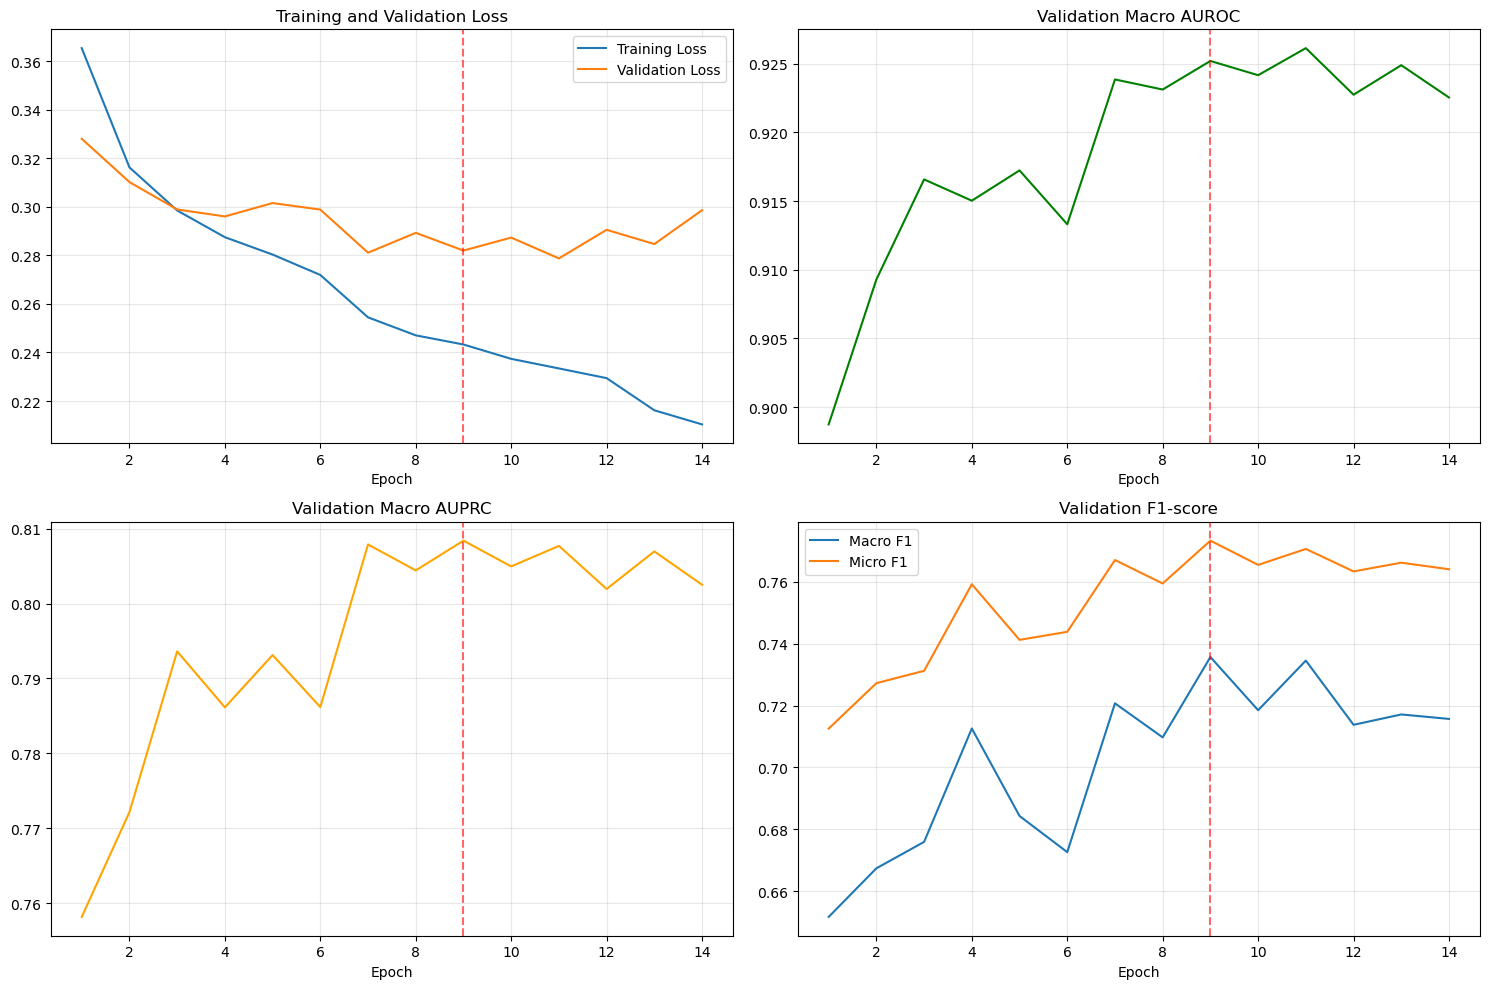

In [68]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss
axes[0, 0].plot(
    epochs, history["train_loss"], label="Training Loss"
)
axes[0, 0].plot(
    epochs, history["val_loss"], label="Validation Loss"
)
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].legend()

# AUROC
axes[0, 1].plot(
    epochs, history["macro_auroc"], color="green"
)
axes[0, 1].set_title("Validation Macro AUROC")

# AUPRC
axes[1, 0].plot(
    epochs, history["macro_auprc"], color="orange"
)
axes[1, 0].set_title("Validation Macro AUPRC")

# F1
axes[1, 1].plot(
    epochs, history["macro_f1"], label="Macro F1"
)
axes[1, 1].plot(
    epochs, history["micro_f1"], label="Micro F1"
)
axes[1, 1].set_title("Validation F1-score")
axes[1, 1].legend()

for ax in axes.flat:

    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.axvline(
        best_epoch,
        color="red",
        linestyle="--",
        alpha=0.6
    )

plt.tight_layout()
plt.savefig(MODEL_DIR / "cnn_training_curves.png", dpi=150)
plt.show()


In [69]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model.to(device)

cnn_metrics, cnn_val_targets, cnn_val_probs = evaluate_model(
    model,
    val_loader,
    criterion
)

cnn_val_preds = (cnn_val_probs >= 0.5).astype(int)

assert np.array_equal(cnn_val_targets, y_val)

print("Best CNN Validation Results")
print("-" * 40)

for metric, value in cnn_metrics.items():

    print(f"{metric}: {value:.4f}")


Best CNN Validation Results
----------------------------------------
loss: 0.2820
macro_auroc: 0.9252
macro_auprc: 0.8084
macro_f1: 0.7357
micro_f1: 0.7733


## Model Comparison

In [70]:
cnn_results = pd.DataFrame([{
    "Model": "1D CNN",
    **get_metrics(y_val, cnn_val_probs, 0.5)
}])

final_val_results = pd.concat(
    [baseline_results, cnn_results],
    ignore_index=True
)

display(final_val_results.round(4))

final_val_results.to_csv(
    MODEL_DIR / "validation_model_comparison.csv",
    index=False
)


,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1,Macro Precision,Macro Recall,Binary Accuracy,Exact Match Accuracy
0,Logistic Regression,0.5086,0.2797,0.0538,0.0990,0.4498,0.0352,0.7348,0.0659
1,SVM,0.5086,0.2803,0.0463,0.0918,0.2857,0.0307,0.7356,0.0626
2,Random Forest,0.6711,0.4140,0.1838,0.3570,0.5533,0.1693,0.7581,0.2982
3,1D CNN,0.9252,0.8084,0.7357,0.7733,0.7860,0.7005,0.8860,0.6224


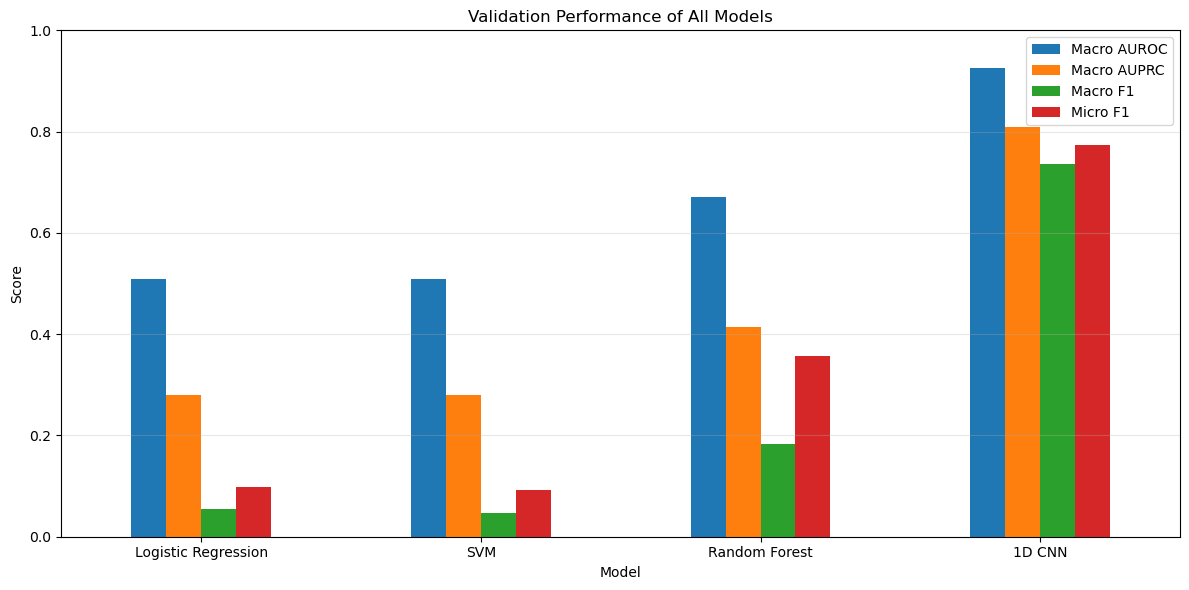

In [71]:
final_val_results.set_index("Model")[
    ["Macro AUROC", "Macro AUPRC", "Macro F1", "Micro F1"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Validation Performance of All Models")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR / "validation_model_comparison.png", dpi=150)
plt.show()


In [72]:
training_times = pd.DataFrame({
    "Model": [
        "Logistic Regression", "SVM",
        "Random Forest", "1D CNN"
    ],

    "Training Time (s)": [
        lr_time, svm_time, rf_time, cnn_time
    ]
})

display(training_times.round(2))

training_times.to_csv(
    MODEL_DIR / "model_training_times.csv",
    index=False
)


,Model,Training Time (s)
0,Logistic Regression,4.23
1,SVM,3.22
2,Random Forest,16.66
3,1D CNN,129.86


## Validation Thresholds

In [73]:
def find_thresholds(y_true, scores):

    thresholds = []

    for i in range(len(selected_labels)):

        precision, recall, values = precision_recall_curve(
            y_true[:, i], scores[:, i]
        )

        f1 = 2 * precision[:-1] * recall[:-1] / (
            precision[:-1] + recall[:-1] + 1e-12
        )

        thresholds.append(values[np.argmax(f1)])

    return np.array(thresholds)


In [74]:
val_scores = {
    "Logistic Regression": lr_val_probs,
    "SVM": svm_val_scores,
    "Random Forest": rf_val_probs,
    "1D CNN": cnn_val_probs
}

default_thresholds = {
    "Logistic Regression": 0.5,
    "SVM": 0.0,
    "Random Forest": 0.5,
    "1D CNN": 0.5
}

thresholds = {}

for name, scores in val_scores.items():

    thresholds[name] = find_thresholds(y_val, scores)

display(pd.DataFrame(thresholds, index=selected_labels))

np.savez(
    MODEL_DIR / "validation_thresholds.npz",
    **thresholds
)


,Logistic Regression,SVM,Random Forest,1D CNN
NORM,0.326969,-0.351031,0.380843,0.486331
MI,0.125287,-0.811665,0.157649,0.405152
STTC,0.057804,-1.108217,0.206334,0.473152
CD,0.017791,-1.481957,0.183370,0.428612
HYP,0.014162,-0.672087,0.163689,0.292837


In [75]:
val_tuned_results = []

for name, scores in val_scores.items():

    val_tuned_results.append({
        "Model": name,
        **get_metrics(y_val, scores, thresholds[name])
    })

val_tuned_results = pd.DataFrame(val_tuned_results)

display(val_tuned_results.round(4))

val_tuned_results.to_csv(
    MODEL_DIR / "validation_tuned_results.csv",
    index=False
)


,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1,Macro Precision,Macro Recall,Binary Accuracy,Exact Match Accuracy
0,Logistic Regression,0.5086,0.2797,0.4036,0.4131,0.2616,0.9970,0.2645,0.0000
1,SVM,0.5086,0.2803,0.4039,0.4419,0.2754,0.8501,0.3929,0.0000
2,Random Forest,0.6711,0.4140,0.4784,0.5001,0.3557,0.7706,0.5719,0.0515
3,1D CNN,0.9252,0.8084,0.7488,0.7784,0.7483,0.7530,0.8839,0.6160


In [76]:
for name, scores in val_scores.items():

    file_name = name.lower().replace(" ", "_")

    np.savez(
        MODEL_DIR / f"{file_name}_validation.npz",
        scores=scores,
        targets=y_val,
        labels=selected_labels,
        ecg_ids=val_df["ecg_id"].to_numpy()
    )


## Test Set Evaluation
Use the selected models and validation thresholds without further tuning.

In [77]:
X_test_signal = get_signals(test_df, "test")

y_test = test_df[selected_labels].to_numpy(
    dtype=np.uint8
)

print("Testing:", X_test_signal.shape, y_test.shape)


Loading test signals: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2163/2163 [00:06<00:00, 318.04it/s]


Testing: (2163, 12, 1000) (2163, 5)


In [78]:
X_test = (
    (X_test_signal - signal_mean) / signal_std
).reshape(len(test_df), -1)

X_test_pca = pca.transform(X_test)

del X_test

print("Test PCA features:", X_test_pca.shape)


Test PCA features: (2163, 256)


In [79]:
lr_test_probs = lr_model.predict_proba(X_test_pca)

svm_test_scores = svm_model.decision_function(X_test_pca)

rf_test_probs = rf_model.predict_proba(X_test_pca)


In [80]:
test_dataset = ECGSignalDataset(
    X_test_signal, test_df, selected_labels
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


In [81]:
cnn_test_metrics, cnn_test_targets, cnn_test_probs = evaluate_model(
    model,
    test_loader,
    criterion
)

assert np.array_equal(cnn_test_targets, y_test)

print("CNN Test Results")

for metric, value in cnn_test_metrics.items():

    print(f"{metric}: {value:.4f}")


CNN Test Results
loss: 0.2809
macro_auroc: 0.9228
macro_auprc: 0.8159
macro_f1: 0.7335
micro_f1: 0.7718


In [82]:
test_scores = {
    "Logistic Regression": lr_test_probs,
    "SVM": svm_test_scores,
    "Random Forest": rf_test_probs,
    "1D CNN": cnn_test_probs
}

test_results = []
test_tuned_results = []

for name, scores in test_scores.items():

    test_results.append({
        "Model": name,
        **get_metrics(y_test, scores, default_thresholds[name])
    })

    test_tuned_results.append({
        "Model": name,
        **get_metrics(y_test, scores, thresholds[name])
    })

test_results = pd.DataFrame(test_results)
test_tuned_results = pd.DataFrame(test_tuned_results)

print("Default thresholds:")
display(test_results.round(4))

print("Validation-tuned thresholds:")
display(test_tuned_results.round(4))


Default thresholds:


,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1,Macro Precision,Macro Recall,Binary Accuracy,Exact Match Accuracy
0,Logistic Regression,0.5050,0.2794,0.0579,0.1104,0.4210,0.0382,0.7393,0.0721
1,SVM,0.5051,0.2799,0.0526,0.1041,0.3524,0.0350,0.7389,0.0693
2,Random Forest,0.6718,0.4207,0.1869,0.3625,0.5712,0.1733,0.7580,0.3024
3,1D CNN,0.9228,0.8159,0.7335,0.7718,0.7877,0.6969,0.8858,0.6315


Validation-tuned thresholds:


,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1,Macro Precision,Macro Recall,Binary Accuracy,Exact Match Accuracy
0,Logistic Regression,0.5050,0.2794,0.4014,0.4112,0.2603,0.9955,0.2631,0.0014
1,SVM,0.5051,0.2799,0.3952,0.4397,0.2692,0.8377,0.3932,0.0014
2,Random Forest,0.6718,0.4207,0.4650,0.4896,0.3450,0.7460,0.5666,0.0569
3,1D CNN,0.9228,0.8159,0.7465,0.7764,0.7460,0.7533,0.8831,0.6181


In [83]:
test_results.to_csv(
    MODEL_DIR / "test_model_comparison.csv",
    index=False
)

test_tuned_results.to_csv(
    MODEL_DIR / "test_tuned_results.csv",
    index=False
)


In [84]:
for name, scores in test_scores.items():

    file_name = name.lower().replace(" ", "_")

    np.savez(
        MODEL_DIR / f"{file_name}_test.npz",
        scores=scores,
        targets=y_test,
        labels=selected_labels,
        ecg_ids=test_df["ecg_id"].to_numpy()
    )


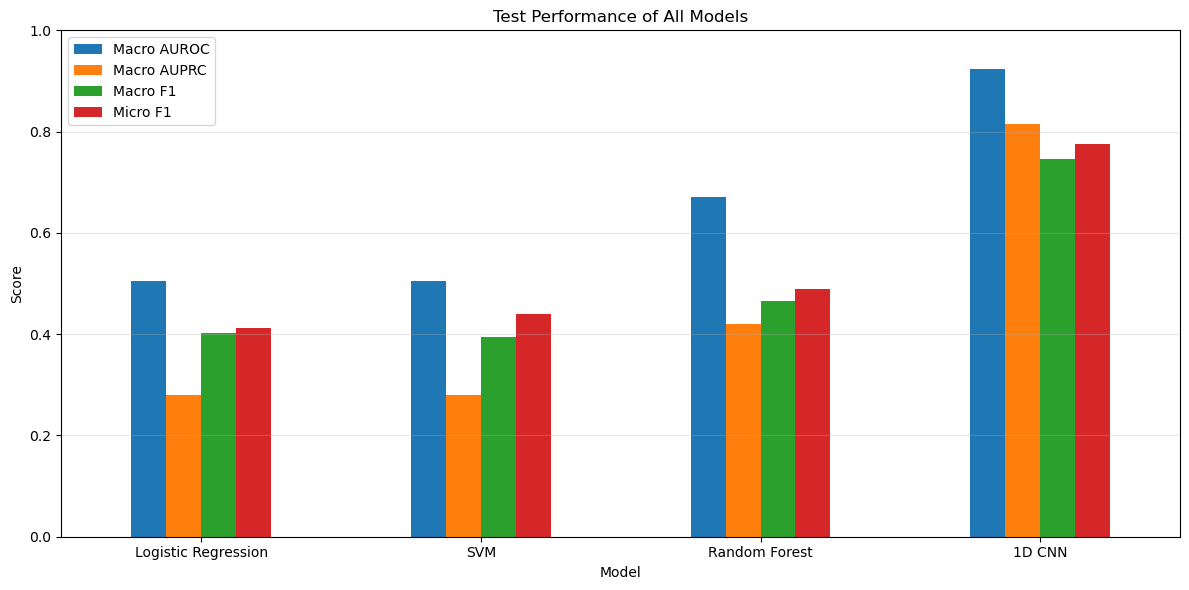

In [85]:
test_tuned_results.set_index("Model")[
    ["Macro AUROC", "Macro AUPRC", "Macro F1", "Micro F1"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Test Performance of All Models")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR / "test_model_comparison.png", dpi=150)
plt.show()


## Per-label Evaluation

In [86]:
per_label_results = []

for name, scores in test_scores.items():

    preds = (scores >= thresholds[name]).astype(int)

    for i, label in enumerate(selected_labels):

        per_label_results.append({
            "Model": name,
            "Label": label,
            "Test Positives": int(y_test[:, i].sum()),

            "AUROC": roc_auc_score(
                y_test[:, i], scores[:, i]
            ),

            "AUPRC": average_precision_score(
                y_test[:, i], scores[:, i]
            ),

            "F1": f1_score(
                y_test[:, i], preds[:, i], zero_division=0
            ),

            "Precision": precision_score(
                y_test[:, i], preds[:, i], zero_division=0
            ),

            "Recall": recall_score(
                y_test[:, i], preds[:, i], zero_division=0
            )
        })

per_label_results = pd.DataFrame(per_label_results)

display(per_label_results.round(4))

per_label_results.to_csv(
    MODEL_DIR / "per_label_test_results.csv",
    index=False
)


,Model,Label,Test Positives,AUROC,AUPRC,F1,Precision,Recall
0,Logistic Regression,NORM,964,0.5194,0.4520,0.6204,0.4524,0.9865
1,Logistic Regression,MI,553,0.4984,0.2576,0.4065,0.2556,0.9928
2,Logistic Regression,STTC,523,0.5082,0.2643,0.3890,0.2416,0.9981
3,Logistic Regression,CD,498,0.5086,0.2832,0.3743,0.2302,1.0000
4,Logistic Regression,HYP,263,0.4906,0.1400,0.2170,0.1217,1.0000
5,SVM,NORM,964,0.5196,0.4526,0.6193,0.4514,0.9865
6,SVM,MI,553,0.4986,0.2579,0.4065,0.2556,0.9928
7,SVM,STTC,523,0.5086,0.2655,0.3890,0.2416,0.9981
8,SVM,CD,498,0.5082,0.2851,0.3737,0.2299,0.9980
9,SVM,HYP,263,0.4906,0.1382,0.1876,0.1677,0.2129


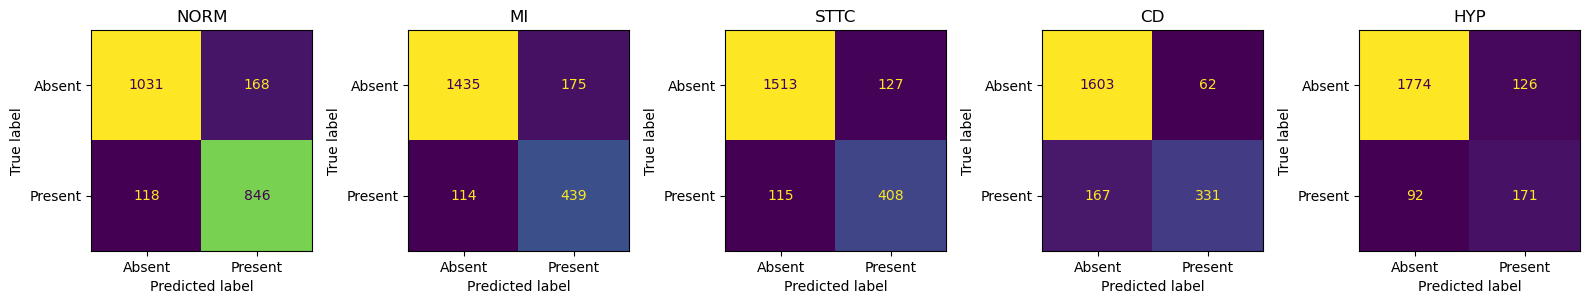

In [87]:
cnn_test_preds = (
    cnn_test_probs >= thresholds["1D CNN"]
).astype(int)

matrices = multilabel_confusion_matrix(
    y_test,
    cnn_test_preds
)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, label, matrix in zip(
    axes, selected_labels, matrices
):

    ConfusionMatrixDisplay(
        matrix,
        display_labels=["Absent", "Present"]
    ).plot(ax=ax, colorbar=False)

    ax.set_title(label)

plt.tight_layout()
plt.savefig(MODEL_DIR / "cnn_test_confusion_matrices.png", dpi=150)
plt.show()
